# 03 · Shared comparison: City A vs City B, models, business answer

**PA04 · Textile storage facility (humid vs. dry regimes) · Guimarães (City A) vs Viana do Castelo (City B) · T4 Humid vs Dry Regime**

* **Business context:** textile storage facility (humid vs. dry regimes)
* **Locations:** Guimarães vs Viana do Castelo
* **Question:** How do humid and dry regimes differ between candidate warehouse locations?

| | Student | Number | Primary city |
|---|---|---|---|
| Student A | Khadija Belhamra | 20230007 | City A: Guimarães |
| Student B | Victoriya Yurevna | 20230796 | City B: Viana do Castelo |

The shared notebook that comes **last**: it pairs the work of both students. It needs the shared protocol (`prepare_frames`), the profile of both cities (`profiling.profile_city`, the same functions as notebooks 01 / 02) and the official results each city notebook saved (`results/metrics_<city>.csv`, `results/history_<city>.csv`).

| Step | Content |
|---|---|
| 1 | Load both cities and both students' results; data and stream construction |
| 2 | Key numbers side by side |
| 3 | Humid regime: frequency, variability, persistence, timing, long spells, simultaneous regimes |
| 4 | Model comparison (both representations, both cities, persistence reference), event detection, why the cities differ |
| 5 | Performance over time |
| 6 | Cost: prediction and update time |
| 7 | Business answer and technical recommendation |

## 1. Load both cities and both students' results

In [1]:
import sys
from pathlib import Path

# Make src/ importable whatever folder Jupyter was started from
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import plots
import profiling
from data import prepare_frames, stream_summary
from evaluate import load_results
from plots import CITY_COLORS, MODEL_COLORS, GREY, INK_2, HUMID, DRY
from utils import load_config, package_version

pd.set_option("display.float_format", lambda v: f"{v:.4f}")
plots.set_style()
cfg = load_config()
prepared = prepare_frames(cfg)
TAU_H = prepared["tau"]
KEYS = [c["key"] for c in cfg["cities"]]                     # City A first, City B second
NAMES = {c["key"]: c["name"] for c in cfg["cities"]}
profiles = {k: profiling.profile_city(f, TAU_H, cfg) for k, f in prepared["frames"].items()}

metrics, history = load_results(cfg)        # saved by 01_cityA_guimaraes and 02_cityB_viana_do_castelo
REF = {k: p["persistence_reference"] for k, p in profiles.items()}
print(f"tau_H = {TAU_H:.2f} %  |  {len(metrics)} runs  |  "
      f"{metrics['n_eval'].iloc[0]} evaluation events per stream  |  cities: {', '.join(NAMES.values())}")

tau_H = 82.00 %  |  20 runs  |  17544 evaluation events per stream  |  cities: Guimaraes, Viana do Castelo


### 1.1 Data and stream construction

Source, period, grid points, warm-up, frozen threshold and package versions (report section 2, Ch. 12.9, 15.2).

In [3]:
display(stream_summary(prepared, cfg))
pd.Series({n: package_version(n) for n in ("pandas", "numpy", "river", "scikit-learn", "matplotlib")},
          name="version").to_frame()


,Guimaraes,Viana do Castelo
role,City A,City B
"grid point (lat, lon)","41.441, -8.288","41.722, -8.857"
elevation (m),170.0000,15.0000
period,2023-01-01 to 2025-12-31,2023-01-01 to 2025-12-31
hours (common timeline),26304,26304
rows flagged invalid,0,0
warm-up hours,8760,8760
evaluation hours,17544,17544
"tau_H (pooled, %)",82.0000,82.0000
"humid share, warm-up",0.5110,0.5000


,version
pandas,2.3.3
numpy,2.5.4
river,0.26.1
scikit-learn,1.9.1
matplotlib,3.11.2


Both streams are hourly gridded weather data from the same API, covering 2023-01-01 to 2025-12-31 (26,304 hours each on a common timeline).

- **Grid points:** Guimarães 41.441, −8.288 (170 m) and Viana do Castelo 41.722, −8.857 (15 m), each within about 4 km of the requested city point.
- **Chronology:** Both streams are complete and strictly hourly, with no duplicates or gaps. The API used a fixed-offset clock, so `timestamp_utc` is stored for local-hour analyses.
- **Warm-up:** 2023 (8,760 h) is used only to set τ_H and the scaler and to warm up the models. 2024–2025 (17,544 h) is evaluated prequentially.
- **τ_H:** 82%, pooled from both cities' warm-up and then frozen. Humid shares are 51.1% / 50.0% in the warm-up and 49.5% / 52.2% in evaluation (Guimarães / Viana).
- **Preprocessing:** No rows were flagged invalid or removed, and extreme values were kept as real weather.
- **Software:** pandas 2.3.3, numpy 2.5.4, river 0.26.1, scikit-learn 1.9.1, matplotlib 3.11.2.

## 2. Key numbers side by side

In [4]:
key = pd.DataFrame({NAMES[k]: p["key_numbers"] for k, p in profiles.items()})
key["B − A"] = key.iloc[:, 1] - key.iloc[:, 0]
key

,Guimaraes,Viana do Castelo,B − A
tau_H,82.0000,82.0000,0.0000
humid_share_all,0.5002,0.5145,0.0143
humid_share_warmup,0.5108,0.5003,-0.0105
humid_share_evaluation,0.4949,0.5215,0.0266
humid_share_DJF,0.5939,0.4783,-0.1156
humid_share_MAM,0.4826,0.4452,-0.0373
humid_share_JJA,0.3665,0.5560,0.1895
humid_share_SON,0.5602,0.5783,0.0182
rh_mean,76.9514,80.4358,3.4845
rh_std,18.2794,12.1777,-6.1017


The overall humid share is almost identical (50.0% vs. 51.4%, 2023–2025), so the difference between the sites lies in timing, persistence and variability.

1. **Summer humid share: 36.7% vs. 55.6% (+18.9 points).** This is the largest seasonal gap. Viana is humid in summer, when Guimarães is dry.
2. **Winter humid share: 59.4% vs. 47.8% (−11.6 points).** The seasonal pattern reverses, so Guimarães's risk falls in winter.
3. **Humid episodes ≥ 24 h: 68 vs. 128.** Viana has almost twice as many long spells (longest 252 h vs. 119 h).
4. **RH variability (24 h std median): 12.8 vs. 7.0.** Guimarães has strong daily swings, while Viana stays more uniformly humid.

All figures cover 2023–2025.

## 3. Humid regime: frequency, persistence, timing

Same τ_H for both cities, so the shares and episode lengths are directly comparable.

### 3.1 Frequency and seasonality of the humid regime

In [5]:
season = pd.DataFrame({NAMES[k]: p["class_by_season"]["humid_share"] for k, p in profiles.items()})
season.loc["all hours"] = [p["key_numbers"]["humid_share_all"] for p in profiles.values()]
season["B − A"] = season.iloc[:, 1] - season.iloc[:, 0]
season

,Guimaraes,Viana do Castelo,B − A
season,,,
DJF,0.5939,0.4783,-0.1156
MAM,0.4826,0.4452,-0.0373
JJA,0.3665,0.5560,0.1895
SON,0.5602,0.5783,0.0182
all hours,0.5002,0.5145,0.0143


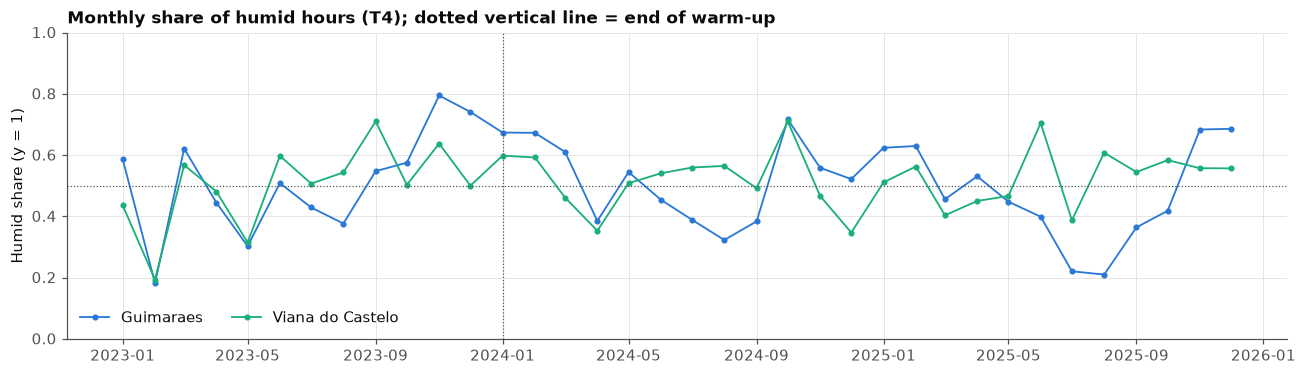

In [6]:
fig = plots.monthly_humid_share(prepared, cfg)
plots.save(fig, cfg, "comparison_01_monthly_humid_share")
plt.show()

Both sites are humid about half the time (50.0% vs. 51.4%, 2023–2025), but in different seasons.

- **Guimarães** is most humid in **winter** (59.4% vs. 47.8%) and driest in summer (36.7%).
- **Viana do Castelo** is most humid in **autumn** (57.8%) and **summer** (55.6%, +18.9 points), and driest in spring (44.5%).
- **Autumn** is humid at both sites, with almost no difference (+1.8 points).
- **Monthly plot:** Viana stays steadier, mostly around or above 50%. Guimarães swings more, with deep summer drops, down to about 20% in July–August 2025.

### 3.2 Variability of humidity and temperature

In [7]:
var = pd.concat({NAMES[k]: p["describe"].loc[:, ["mean", "std", "5%", "50%", "95%", "min", "max"]]
                 for k, p in profiles.items()}, axis=0).swaplevel().sort_index(level=0, sort_remaining=False)
var

mean     std      5%     50%  \
Precipitation (mm)    Guimaraes         0.2079  0.7718  0.0000  0.0000   
                      Viana do Castelo  0.2021  0.7592  0.0000  0.0000   
Relative humidity (%) Guimaraes        76.9514 18.2794 42.0000 82.0000   
                      Viana do Castelo 80.4358 12.1777 58.0000 82.0000   
Temperature (°C)      Guimaraes        15.6038  6.5583  5.4000 15.1000   
                      Viana do Castelo 15.3981  4.1052  8.5000 15.4000   
Wind speed (km/h)     Guimaraes         9.6913  5.9435  2.2000  8.6000   
                      Viana do Castelo 15.3934  9.0656  3.3000 14.1000   

                                           95%     min      max  
Precipitation (mm)    Guimaraes         1.2000  0.0000  17.7000  
                      Viana do Castelo  1.2000  0.0000  16.1000  
Relative humidity (%) Guimaraes        98.0000 13.0000 100.0000  
                      Viana do Castelo 97.0000 27.0000 100.0000  
Temperature (°C)      Guimaraes        27.5000 -1.5000  39.8000  
                      Viana do Castelo 21.9000  1.6000  30.9000  
Wind speed (km/h)     Guimaraes        20.9000  0.0000  44.0000  
                      Viana do Castelo 31.9000  0.0000  57.5000

The coastal position of Viana do Castelo shows up as much lower variability in both RH and temperature (2023–2025).

- **RH:** Viana is more humid on average (80.4% vs. 77.0%) but much less variable (std 12.2 vs. 18.3). Its dry extremes are milder (P5 58% vs. 42%, min 27% vs. 13%). The medians are the same (82%), so the difference is in the spread, not the typical value.
- **Temperature:** Viana has similar mean temperatures (15.4 vs. 15.6 °C) but a much narrower range (std 4.1 vs. 6.6; P5–P95 8.5–21.9 °C vs. 5.4–27.5 °C). It has neither frost nor strong heat (min 1.6 vs. −1.5 °C, max 30.9 vs. 39.8 °C).
- **Wind:** Viana is clearly windier (mean 15.4 vs. 9.7 km/h).
- **Precipitation** is almost identical at both sites.

**Takeaway:** The sea dampens extremes in Viana, keeping RH high and stable. Inland Guimarães has larger swings, including the hot, very dry hours that create its dry regime.

### 3.3 Persistence: how long humid and dry regimes last

In [8]:
pd.concat({NAMES[k]: p["persistence"] for k, p in profiles.items()}, axis=1)

Guimaraes           Viana do Castelo  \
                                               dry     humid              dry   
episodes                                 1052.0000 1053.0000        1114.0000   
mean (h)                                   12.4962   12.4957          11.4641   
median (h)                                 10.0000   12.0000           6.5000   
P90 (h)                                    20.0000   20.0000          24.0000   
max (h)                                   235.0000  119.0000         237.0000   
episodes ≥ 24 h                            75.0000   68.0000         114.0000   
episodes ≥ 72 h                            11.0000    5.0000          14.0000   
share of regime hours in episodes ≥ 24 h    0.3318    0.2480           0.4654   

                                                    
                                             humid  
episodes                                 1115.0000  
mean (h)                                   12.1372  
median (h)                                  7.0000  
P90 (h)                                    26.0000  
max (h)                                   252.0000  
episodes ≥ 24 h                           128.0000  
episodes ≥ 72 h                            15.0000  
share of regime hours in episodes ≥ 24 h    0.4518

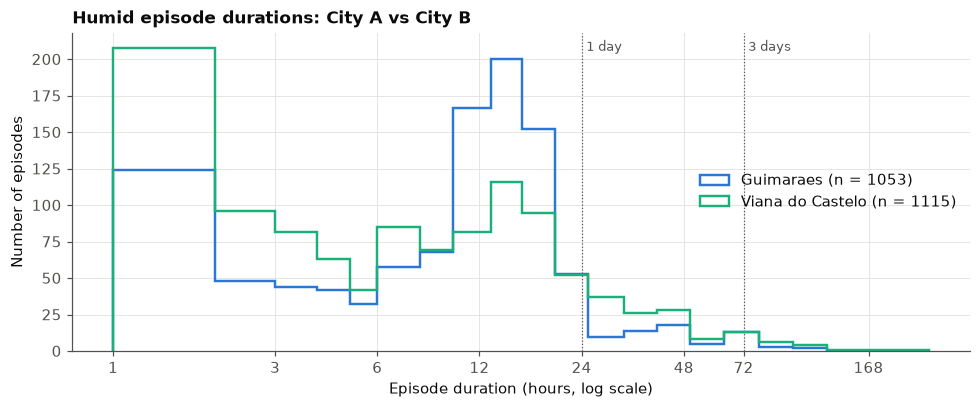

In [9]:
fig = plots.compare_episode_durations(profiles, cfg)
plots.save(fig, cfg, "comparison_02_humid_episode_durations")
plt.show()

The humid regime is clearly more persistent in Viana do Castelo, even though both sites are humid about equally often (2023–2025).

- **Long spells:** Viana has 128 vs. 68 humid episodes ≥ 24 h, 15 vs. 5 episodes ≥ 72 h, and a longest spell of 252 h vs. 119 h. 45% of its humid hours fall in spells of at least a day, against 25% in Guimarães.
- **Short episodes:** Viana also has many more very short episodes (median 7 h vs. 12 h, with a large 1–2 h peak). Its humid episodes are either brief flickers or long spells. Guimarães's cluster at 12–24 h, following the day–night cycle.
- **Why persistence matters more for textiles:** A short humid episode is followed by a dry break in which stored textiles can release moisture. A long spell gives no break, so moisture keeps building up and the risk of mould and damage grows with every hour. Two sites with the same humid share can therefore pose very different risks. Viana's longer spells make it the more demanding site, even though its overall humid share is only slightly higher.

### 3.4 Timing: month × local hour

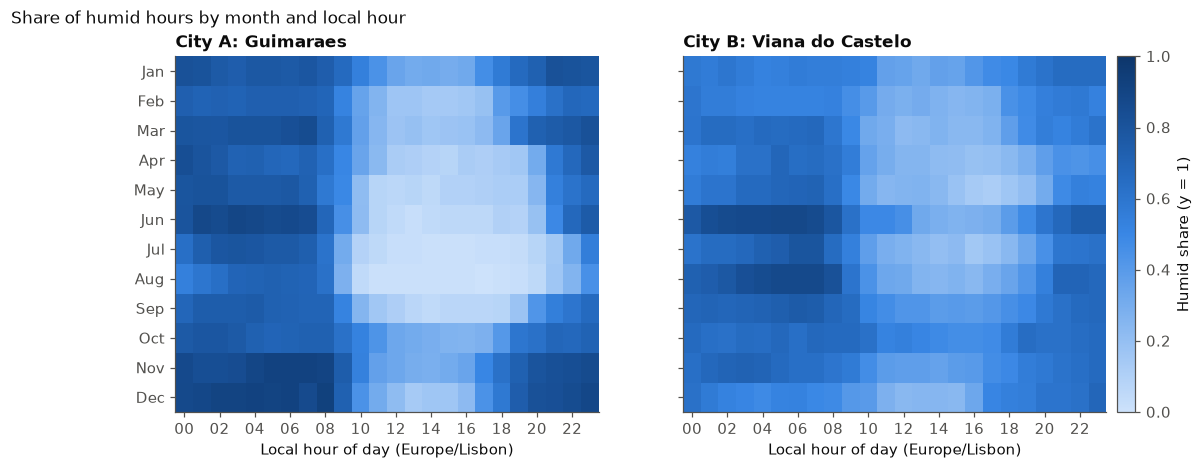

Guimaraes                                         \
       most humid hour least humid hour amplitude (max - min)   
season                                                          
DJF                  0               15                0.6052   
MAM                  0               14                0.7065   
JJA                  3               13                0.7754   
SON                  2               14                0.5788   

       Viana do Castelo                                         
        most humid hour least humid hour amplitude (max - min)  
season                                                          
DJF                  23               15                0.3469  
MAM                   7               16                0.4928  
JJA                   6               16                0.6268  
SON                   5               14                0.2821

In [10]:
fig = plots.compare_hour_month(profiles, cfg)
plots.save(fig, cfg, "comparison_03_hour_month")
plt.show()
pd.concat({NAMES[k]: p["daily_cycle"][["most humid hour", "least humid hour", "amplitude (max - min)"]]
           for k, p in profiles.items()}, axis=1)

Both sites are most humid at night and early morning and least humid in the afternoon, but the daily contrast is much stronger in Guimarães (2023–2025).

- **Guimarães:** Its most humid hours are around midnight to 03 h and its least humid around 13–15 h. The day–night amplitude is large in every season (0.58–0.78). A clear dry window from late morning to late afternoon is reliable from spring to early autumn, and shorter and weaker in winter.
- **Viana do Castelo:** Its most humid hours come later, in the early morning (05–07 h, and 23 h in winter), and its least humid around 14–16 h. The amplitude is much smaller (0.28–0.63). The dry window is weaker, and in autumn and winter it is barely visible. Summer nights and mornings (June–August) are among its most humid hours.

**Ventilation:**
- **Guimarães** offers a dependable afternoon window for most of the year.
- **Viana** offers a usable afternoon window only in spring and summer, and even then it is less dry. In autumn and winter it should rely on dehumidification rather than ventilation.

### 3.5 Long humid spells (≥ 24 h), month by month

Original analysis (Ch. 3.2), the same definition as the long-spell analysis in the city notebooks (Step 11 in notebook 01, Section 8.3 in notebook 02): **risk hours** are humid hours inside an episode of at least 24 h, i.e. the hours a store spends in a sustained humid spell.

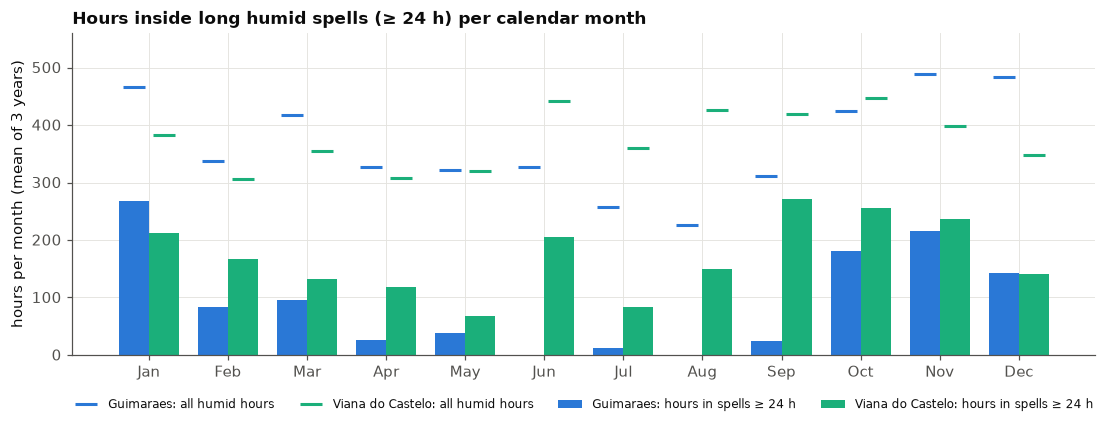

,Guimaraes,Viana do Castelo
risk hours per year,1087.6667,2038.0000
share of humid hours in spells ≥ 24 h,0.2480,0.4518


In [11]:
LONG_H = 24

def risk_hours(p):
    d = p["df"]
    run_id = (d["y"] != d["y"].shift()).cumsum()
    run_len = d.groupby(run_id)["y"].transform("size")
    return d.assign(risk=(d["y"] == 1) & (run_len >= LONG_H), humid=d["y"] == 1)

monthly = {k: risk_hours(p).groupby("month")[["humid", "risk"]].sum() / 3 for k, p in profiles.items()}   # 3 years
fig, ax = plt.subplots(figsize=(12, 3.8))
x = np.arange(12)
for i, (k, color) in enumerate(zip(KEYS, CITY_COLORS)):
    ax.bar(x + (i - 0.5) * 0.38, monthly[k]["risk"], 0.38, color=color, label=f"{NAMES[k]}: hours in spells ≥ {LONG_H} h")
    ax.plot(x + (i - 0.5) * 0.38, monthly[k]["humid"], "_", color=color, markersize=14, markeredgewidth=2,
            label=f"{NAMES[k]}: all humid hours")
ax.set_xticks(x, plots.MONTHS)
ax.set_ylabel("hours per month (mean of 3 years)")
ax.set_title(f"Hours inside long humid spells (≥ {LONG_H} h) per calendar month", loc="left")
ax.set_ylim(0, 560)
ax.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1))
plots.save(fig, cfg, "comparison_04_long_humid_spells")
plt.show()

long_tbl = pd.DataFrame({NAMES[k]: {"risk hours per year": r["risk"].sum() / 3,
                                    "share of humid hours in spells ≥ 24 h": r["risk"].sum() / r["humid"].sum()}
                         for k, r in ((k, risk_hours(p)) for k, p in profiles.items())})
long_tbl

Viana do Castelo exposes the store to far more sustained humidity, with about 2,040 risk hours per year against about 1,090 in Guimarães (mean of 2023–2025).

- **Share:** 45% of Viana's humid hours fall in spells ≥ 24 h, against 25% in Guimarães.
- **Guimarães:** Sustained spells are concentrated from October to January (highest in January), with almost none from April to September.
- **Viana:** Sustained spells occur almost all year. They peak from September to November and are also high in January and June. Even July and August have clearly more risk hours than in Guimarães.
- **Comparison:** Guimarães exceeds Viana only in January, and the two are about equal in December. In every other month Viana has more risk hours, with the largest gaps from June to September.

>**Takeaway:** Guimarães needs heavy dehumidification only in autumn and winter, while Viana needs sustained capacity for most of the year.

### 3.6 Are both sites humid at the same time?

Original analysis (Ch. 3.2). Both streams share the same timestamps, so each hour can be classified by the regime in **both** cities. If the two sites were often in different regimes, the choice of site would matter hour by hour; if they move together, the difference is mainly in how often and how long.

viana_do_castelo,Viana do Castelo dry,Viana do Castelo humid
guimaraes,,
Guimaraes dry,0.3663,0.1334
Guimaraes humid,0.1192,0.3810


,same regime,only A humid,only B humid
season,,,
DJF,0.7371,0.1893,0.0736
MAM,0.7799,0.1287,0.0914
JJA,0.7275,0.0415,0.2310
SON,0.7448,0.1185,0.1367
all,0.7474,0.1192,0.1334


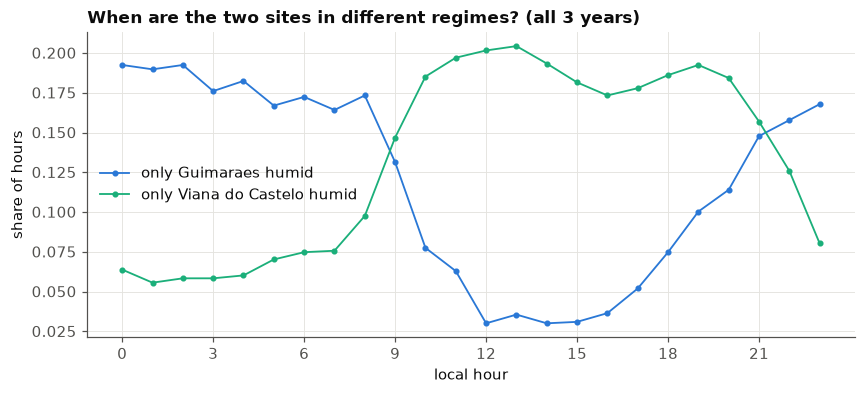

In [12]:
both = pd.DataFrame({k: prepared["frames"][k].set_index("timestamp")["y"] for k in KEYS}).dropna()
agree = pd.crosstab(both[KEYS[0]].map({0: f"{NAMES[KEYS[0]]} dry", 1: f"{NAMES[KEYS[0]]} humid"}),
                    both[KEYS[1]].map({0: f"{NAMES[KEYS[1]]} dry", 1: f"{NAMES[KEYS[1]]} humid"}), normalize=True)
display(agree)

hours = profiles[KEYS[0]]["df"].set_index("timestamp")[["hour", "season"]]
by = both.join(hours)
by["same regime"] = by[KEYS[0]] == by[KEYS[1]]
by["only B humid"] = (by[KEYS[1]] == 1) & (by[KEYS[0]] == 0)
by["only A humid"] = (by[KEYS[0]] == 1) & (by[KEYS[1]] == 0)
table = by.groupby("season", observed=True)[["same regime", "only A humid", "only B humid"]].mean()
table.loc["all"] = by[["same regime", "only A humid", "only B humid"]].mean()
display(table)

fig, ax = plt.subplots(figsize=(9, 3.6))
h = by.groupby("hour")[["only A humid", "only B humid"]].mean()
ax.plot(h.index, h["only A humid"], color=CITY_COLORS[0], marker="o", markersize=3, label=f"only {NAMES[KEYS[0]]} humid")
ax.plot(h.index, h["only B humid"], color=CITY_COLORS[1], marker="o", markersize=3, label=f"only {NAMES[KEYS[1]]} humid")
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel("local hour"); ax.set_ylabel("share of hours")
ax.set_title("When are the two sites in different regimes? (all 3 years)", loc="left")
ax.legend()
plots.save(fig, cfg, "comparison_05_regime_disagreement_by_hour")
plt.show()

**1. When one site is humid, is the other too?**

Mostly yes. The two sites are in the same regime 74.7% of the time (2023–2025).

- When Guimarães is humid, Viana is also humid about 76% of the time. When Viana is humid, Guimarães is also humid about 74% of the time.
- **By hour, the disagreements are mirror images:**
  - At **night and early morning (00–08 h)**, mostly only Guimarães is humid (about 17–19% of hours).
  - In **daytime (10–20 h)**, mostly only Viana is humid (about 17–20% of hours).
  - The two cross around 09 h and 21 h.
- **By season:** "Only Guimarães humid" peaks in winter (18.9%), and "only Viana humid" peaks in summer (23.1%).

**2. Where is the humid regime more frequent, more persistent, and at which times?**

The sites share the same regime most of the time, but they differ in frequency by season, in persistence, and in time of day. The difference is both seasonal and daily (2023–2025).

- **Frequency:** Viana is slightly more humid overall (51.4% vs. 50.0%), but Guimarães is more humid in winter (59.4% vs. 47.8%) and Viana in summer (55.6% vs. 36.7%).
- **Persistence:** Viana is clearly more persistent, with 128 vs. 68 spells ≥ 24 h and about 2,040 vs. 1,090 risk hours per year.
- **Daily:** Guimarães is humid at night and dry in the afternoon. Viana stays humid during the day, when Guimarães dries out.
- **Answer:** Both. The seasonal difference is winter (Guimarães) vs. summer (Viana), and the daily difference is a strong day–night cycle (Guimarães) vs. persistent daytime humidity (Viana).

## 4. Model comparison

Same chronological history, same features and same models for both cities (Ch. 3.1). The dashed lines are the persistence rule ŷ_t = y_{t−1} of each city (`profiling.persistence_reference`, evaluation stream only).

### 4.1 Macro-F1 against persistence

In [13]:
table = metrics.pivot_table(index="model", columns=["city", "representation"], values="macro_f1", sort=False)
table.columns = [f"{NAMES[c]} · {r}" for c, r in table.columns]
table.loc["persistence y_t-1"] = [REF[c]["macro_f1"] for c in KEYS for _ in ("A", "B")]
display(table)

delta = metrics.assign(delta=metrics["macro_f1"] - metrics["city"].map(lambda c: REF[c]["macro_f1"]))
d = delta.pivot_table(index="model", columns=["city", "representation"], values="delta", sort=False)
d.columns = [f"{NAMES[c]} · {r}" for c, r in d.columns]
d.style.format("{:+.4f}").background_gradient(cmap="RdBu", vmin=-0.05, vmax=0.05).set_caption("Δ Macro-F1 vs persistence")

,Guimaraes · A,Guimaraes · B,Viana do Castelo · A,Viana do Castelo · B
model,,,,
Gaussian Naive Bayes,0.9125,0.8798,0.8833,0.8606
Online Logistic Regression,0.8907,0.9066,0.8593,0.8631
Hoeffding Tree,0.9195,0.9342,0.9104,0.9139
Online Bagging,0.9204,0.9415,0.9131,0.9155
Adaptive Random Forest,0.9191,0.9364,0.9104,0.9127
persistence y_t-1,0.9204,0.9204,0.9140,0.9140


,Guimaraes · A,Guimaraes · B,Viana do Castelo · A,Viana do Castelo · B
model,,,,
Gaussian Naive Bayes,-0.0079,-0.0406,-0.0307,-0.0534
Online Logistic Regression,-0.0297,-0.0138,-0.0547,-0.0509
Hoeffding Tree,-0.0010,+0.0138,-0.0036,-0.0001
Online Bagging,-0.0000,+0.0211,-0.0009,+0.0015
Adaptive Random Forest,-0.0014,+0.0160,-0.0036,-0.0013


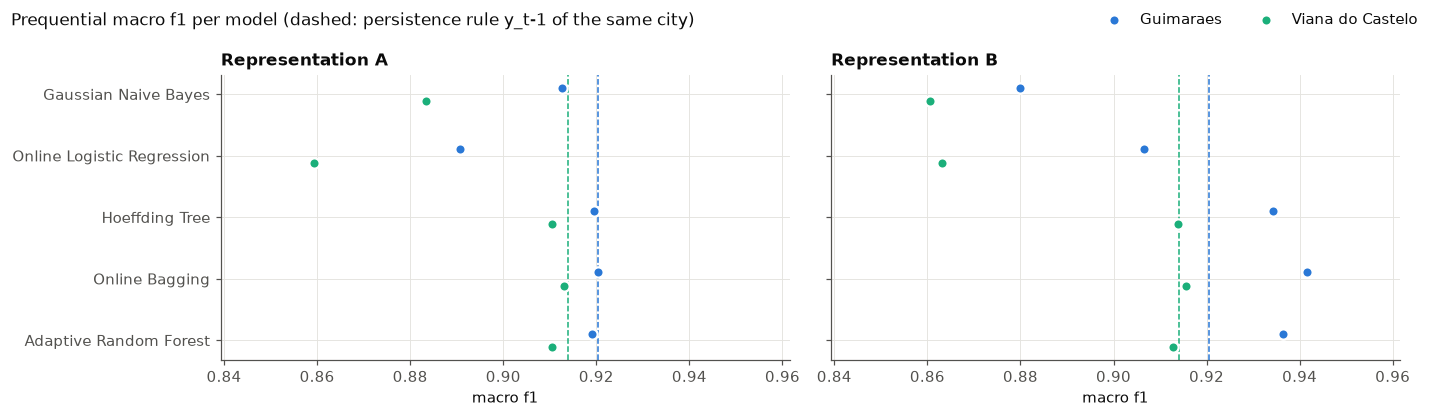

In [14]:
fig = plots.compare_models(metrics, REF, cfg, "macro_f1")
plots.save(fig, cfg, "comparison_06_macro_f1")
plt.show()

Models add clear value over persistence only in Guimarães with Representation B (evaluation 2024–2025).

- **Guimarães B:** Three models beat persistence (0.9204): Online Bagging +0.021, ARF +0.016 and Hoeffding Tree +0.014.
- **Guimarães A:** No model beats persistence. Online Bagging only matches it.
- **Viana do Castelo:** No meaningful gain. Only Online Bagging B is above persistence (0.9140), and only by +0.0015, which is practically equal. Context barely helps the tree models in Viana.
- **Weak models in both cities:** Gaussian NB and Logistic Regression stay clearly below persistence in all four settings, and the gap is larger in Viana (down to −0.055).

**Likely reason:** Guimarães's strong daily cycle gives the context features a pattern to learn. Viana's weak daily cycle and many short episodes near τ_H give them little to work with.

### 4.2 Does temporal context help? Representation B − A per city

**Common comparison question (Ch. 8).** Same models and events; only the representation changes.

In [15]:
gain = metrics.pivot_table(index="model", columns=["city", "representation"], values="macro_f1", sort=False)
pd.DataFrame({NAMES[c]: gain[(c, "B")] - gain[(c, "A")] for c in KEYS}).style.format("{:+.4f}")

,Guimaraes,Viana do Castelo
model,,
Gaussian Naive Bayes,-0.0327,-0.0227
Online Logistic Regression,+0.0159,+0.0037
Hoeffding Tree,+0.0148,+0.0035
Online Bagging,+0.0211,+0.0024
Adaptive Random Forest,+0.0174,+0.0023


Recent context (Representation B) helps four of the five learners in both cities, but the gain is about five times larger in Guimarães (evaluation 2024–2025).

- **Guimarães:** The gains are clear. Online Bagging improves by +0.021, ARF by +0.017, Logistic Regression by +0.016 and Hoeffding Tree by +0.015, which is enough for the tree models to beat persistence.
- **Viana do Castelo:** The gains are small (+0.002 to +0.004) and don't lift any model meaningfully above persistence.
- **Gaussian NB** gets worse in both cities (−0.033 and −0.023), likely because the context features overlap with each other and with current RH, which breaks its independence assumption.

**Why the sites differ:** The rolling features capture daily swings and the difference between stable and changing conditions. Guimarães has a strong, regular day–night cycle (24 h std median 12.8), so context carries useful information about the next switch. Viana's RH is steadier (7.0), its daily cycle is weak, and many of its switches are short flickers near τ_H, so recent context adds little beyond the current value.

### 4.3 Event detection: Precision, Recall and errors on the humid class

**Ch. 11.1:** positive class = humid. A missed humid hour (false negative) means the store is not warned; a false alarm (false positive) means unnecessary dehumidification.

In [16]:
ev = metrics.assign(**{
    "missed humid %": 100 * metrics["fn"] / (metrics["fn"] + metrics["tp"]),
    "false alarm %": 100 * metrics["fp"] / (metrics["fp"] + metrics["tn"]),
})
ev = ev.pivot_table(index="model", columns=["city", "representation"],
                    values=["precision", "recall", "missed humid %", "false alarm %"], sort=False)
ev.columns = [f"{m} · {NAMES[c]} · {r}" for m, c, r in ev.columns]
ev.T

model,Gaussian Naive Bayes,Online Logistic Regression,Hoeffding Tree,Online Bagging,Adaptive Random Forest
precision · Guimaraes · A,0.9319,0.8585,0.9178,0.9208,0.9155
precision · Guimaraes · B,0.8992,0.8841,0.9233,0.9372,0.9334
precision · Viana do Castelo · A,0.9419,0.8383,0.9220,0.9190,0.9110
precision · Viana do Castelo · B,0.8773,0.8602,0.9244,0.9111,0.9188
recall · Guimaraes · A,0.8884,0.9333,0.9196,0.9182,0.9216
recall · Guimaraes · B,0.8530,0.9338,0.9456,0.9452,0.9385
recall · Viana do Castelo · A,0.8274,0.9072,0.9050,0.9142,0.9184
recall · Viana do Castelo · B,0.8521,0.8815,0.9096,0.9291,0.9137
missed humid % · Guimaraes · A,11.1597,6.6682,8.0387,8.1769,7.8429
missed humid % · Guimaraes · B,14.6954,6.6221,5.4359,5.4820,6.1499


A missed humid hour is the costlier error for a textile store, because moisture builds up without any response. A false alarm only costs unnecessary dehumidification (evaluation 2024–2025).

- **Guimarães:** Online Bagging B is the best detector. It misses 5.5% of humid hours (Hoeffding Tree B is almost identical at 5.4%) with the fewest false alarms among the strong models (6.2%).
- **Viana do Castelo:** Online Bagging B also misses the fewest humid hours (7.1%). That is fewer than persistence (about 8.2%, recall 0.918), even though its Macro-F1 barely differs. The trade-off is more false alarms (9.9%).
- **Across both cities,** humid hours are harder to catch in Viana. Every strong model misses more there than in Guimarães.
- **Avoid:** Gaussian NB misses the most (up to 17.3%). Logistic Regression raises the most false alarms (up to 19.1%).

> **Takeaway:** Online Bagging B is the best choice in both cities for catching humid hours. In Viana, its main advantage over persistence is fewer missed humid hours rather than a higher overall score.

### 4.4 Why are the two cities different to predict?

Linking the descriptive evidence (Section 3) to the predictive evidence (sections 4.1–4.3), as the rubric asks (Ch. 13.3, 17). All measures on the evaluation period 2024–2025.

In [17]:
rows = {}
for k, p in profiles.items():
    d = p["df"][p["df"]["phase"] == "evaluation"]
    y, y_prev = d["y"], p["df"]["y"].shift(1)[d.index]
    best = metrics[metrics["city"] == k].sort_values("macro_f1").iloc[-1]
    rows[NAMES[k]] = {
        "regime switches per day": (y != y_prev).mean() * 24,
        "hours where the regime switches (%)": 100 * (y != y_prev).mean(),
        "hours within ±3 pp of τ_H (%)": 100 * ((d["relative_humidity_2m"] - TAU_H).abs() <= 3).mean(),
        "median 6 h std of RH (pp)": p["rolling"].loc[d["timestamp"], "rh_std_6h"].median(),
        "daily-cycle amplitude, mean of seasons": p["daily_cycle"]["amplitude (max - min)"].mean(),
        "persistence Macro-F1": REF[k]["macro_f1"],
        "best model": f"{best['model']} · {best['representation']}",
        "best Macro-F1": best["macro_f1"],
        "gain over persistence": best["macro_f1"] - REF[k]["macro_f1"],
    }
pd.DataFrame(rows)

,Guimaraes,Viana do Castelo
regime switches per day,1.9097,2.0602
hours where the regime switches (%),7.9571,8.5841
hours within ±3 pp of τ_H (%),12.1979,20.7820
median 6 h std of RH (pp),5.1153,3.1411
"daily-cycle amplitude, mean of seasons",0.6665,0.4371
persistence Macro-F1,0.9204,0.9140
best model,Online Bagging · B,Online Bagging · B
best Macro-F1,0.9415,0.9155
gain over persistence,0.0211,0.0015


Both cities switch regime about equally often, so the difference lies in *how* the switches happen: in Guimarães they follow a predictable daily rhythm, while in Viana do Castelo they are small fluctuations around the threshold.

- **Switch frequency is similar:** 1.9 vs. 2.1 per day, and 8.0% vs. 8.6% of hours. This alone doesn't explain the gap.
- **Daily rhythm:** Guimarães has a much stronger daily cycle (amplitude 0.67 vs. 0.44), so its switches happen at regular times (evening rise, late-morning drop) that rolling features can anticipate.
- **Closeness to τ_H:** Viana spends far more time near the threshold (20.8% vs. 12.2% of hours within ±3 points). There, tiny changes in RH flip the label, which is hard to predict for any model.
- **Short-term variability:** RH in Viana moves less (median 6 h std 3.1 vs. 5.1), so recent context carries little signal about an upcoming switch.

**Result:** In Guimarães the best model gains +0.021 over persistence. In Viana it gains only +0.0015, which is practically none (evaluation 2024–2025).

## 5. Performance over time

Sliding-window Macro-F1 over the last `protocol.evaluation_window` events. Drops show periods where the models adapt to a changed regime.

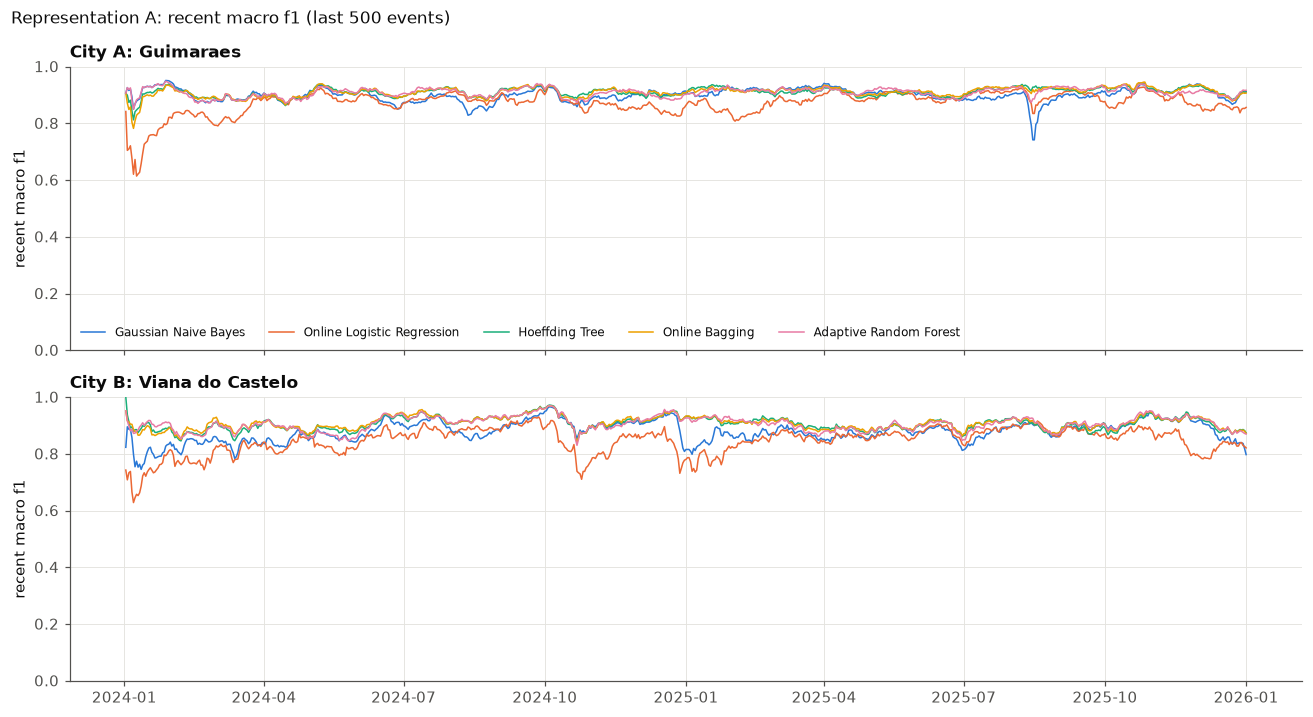

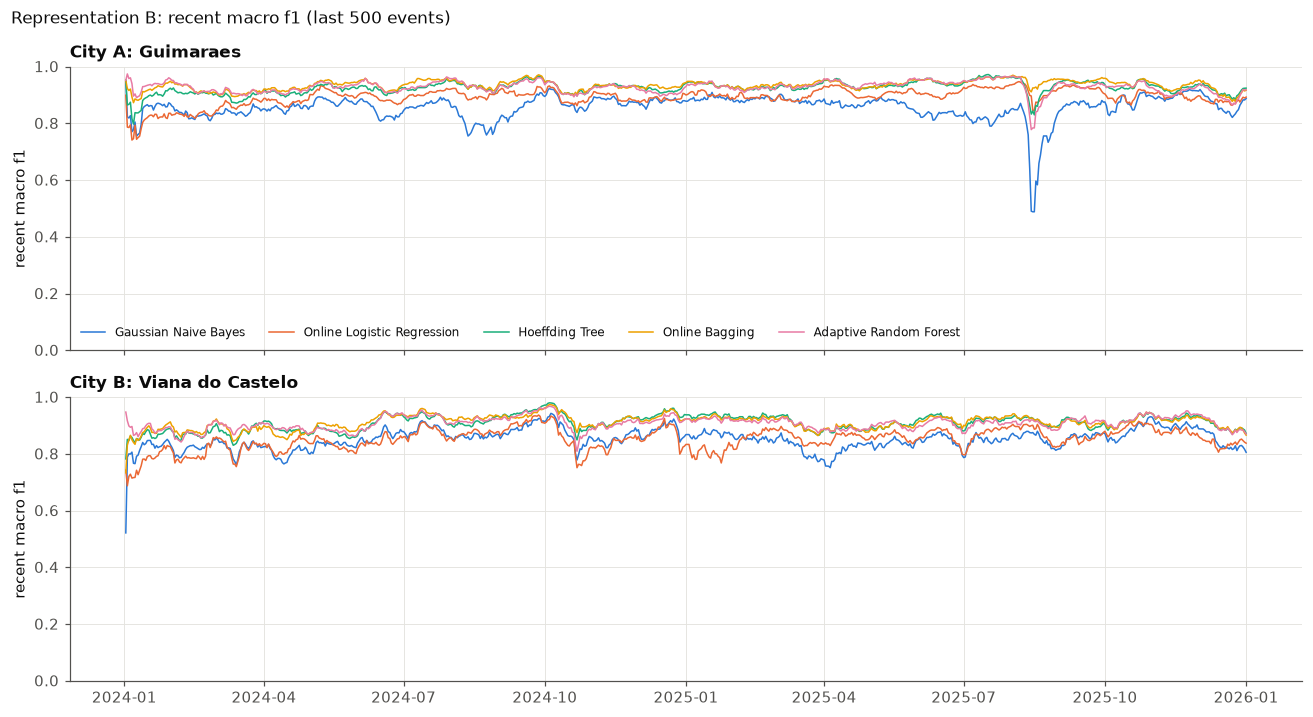

,Guimaraes,Viana do Castelo
season,,
DJF,0.9018,0.8830
JJA,0.9068,0.8975
MAM,0.9080,0.8663
SON,0.9155,0.9018


In [18]:
for rep in ("A", "B"):
    fig = plots.recent_performance(history, cfg, representation=rep)
    plots.save(fig, cfg, f"comparison_07_recent_macro_f1_{rep}")
    plt.show()

W = cfg["protocol"]["evaluation_window"]
hb = history[(history["representation"] == "B") & (history["n"] >= W)]
seasons = {k: p["df"].set_index("timestamp")["season"] for k, p in profiles.items()}
hb = hb.assign(season=[seasons[c].loc[t] for c, t in zip(hb["city"], hb["timestamp"])])
s = hb.pivot_table(index="season", columns="city", values="recent_macro_f1", aggfunc="mean", observed=True)
s.columns = [NAMES[c] for c in s.columns]
s

The broad ranking is stable over time in both cities, but the top three models swap places from window to window (evaluation 2024–2025).

- **Ranking:** The three tree-based models (Online Bagging, ARF, Hoeffding Tree) stay close together at the top almost all the time, without a fixed order among them. Gaussian NB and Logistic Regression are lower in most windows and drop the most during difficult periods: NB in Guimarães B in August 2025, and Logistic Regression in Viana around October 2024.
- **Representation B** keeps the tree models more clearly ahead of the rest in Guimarães. In Viana the lines stay closer together in both representations.
- **Hardest season:**
  - **Guimarães:** The seasons are almost equal (0.902–0.916). Winter is marginally the hardest, and the city's largest single drop comes in the extreme dry spell of August 2025.
  - **Viana do Castelo:** Spring is clearly the hardest (0.866), followed by winter (0.883). Autumn is the easiest (0.902).
- **Overall,** Viana is harder to predict than Guimarães in every season.

## 6. Cost: prediction and update time per event

pred_ms_per_event                                 \
city                               guimaraes        viana_do_castelo          
representation                             A      B                A      B   
model                                                                         
Gaussian Naive Bayes                  0.0283 0.0260           0.0232 0.0262   
Online Logistic Regression            0.0004 0.0005           0.0004 0.0005   
Hoeffding Tree                        0.0023 0.0022           0.0022 0.0022   
Online Bagging                        0.0123 0.0130           0.0128 0.0134   
Adaptive Random Forest                0.0191 0.0182           0.0174 0.0169   

                           update_ms_per_event                                 
city                                 guimaraes        viana_do_castelo         
representation                               A      B                A      B  
model                                                                          
Gaussian Naive Bayes                    0.0012 0.0017           0.0009 0.0016  
Online Logistic Regression              0.0010 0.0012           0.0009 0.0012  
Hoeffding Tree                          0.0044 0.0075           0.0045 0.0086  
Online Bagging                          0.0243 0.0437           0.0267 0.0472  
Adaptive Random Forest                  0.1519 0.1467           0.1110 0.1200

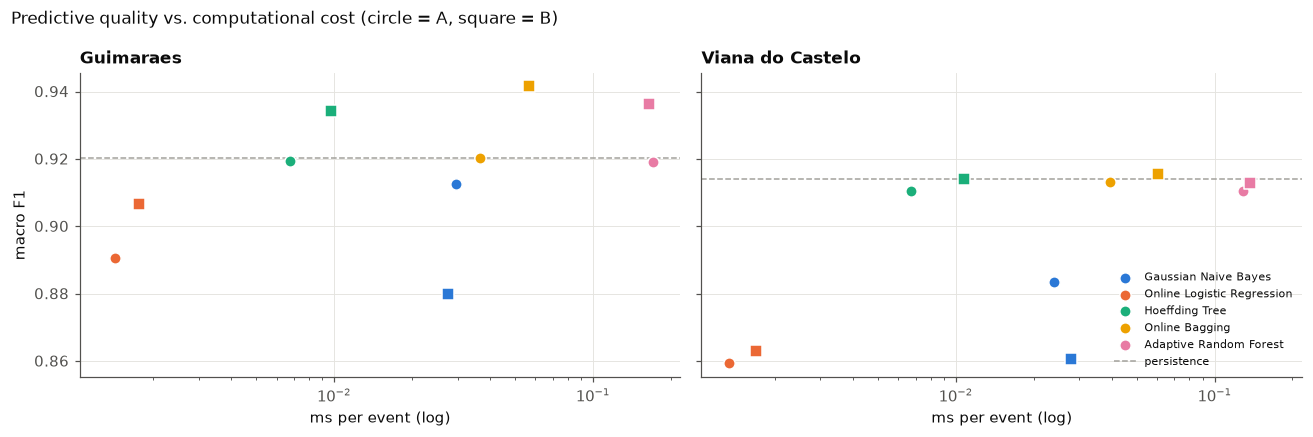

In [19]:
cost = metrics.assign(total_ms=metrics["pred_ms_per_event"] + metrics["update_ms_per_event"])
display(cost.pivot_table(index="model", columns=["city", "representation"],
                         values=["pred_ms_per_event", "update_ms_per_event"], sort=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
markers = {"A": "o", "B": "s"}
models = list(dict.fromkeys(metrics["model"]))
for ax, k in zip(axes, KEYS):
    sub = cost[cost["city"] == k]
    for m, color in zip(models, MODEL_COLORS):
        for rep in ("A", "B"):
            r = sub[(sub["model"] == m) & (sub["representation"] == rep)].iloc[0]
            ax.scatter(r["total_ms"], r["macro_f1"], s=55, color=color, marker=markers[rep], edgecolor="white",
                       zorder=3, label=m if rep == "A" else None)
    ax.axhline(REF[k]["macro_f1"], color=GREY, linestyle="--", linewidth=1, label="persistence")
    ax.set_xscale("log"); ax.set_title(NAMES[k], loc="left"); ax.set_xlabel("ms per event (log)")
axes[0].set_ylabel("macro F1")
axes[1].legend(fontsize=7, loc="lower right")
fig.suptitle("Predictive quality vs. computational cost (circle = A, square = B)", x=0.01, ha="left")
fig.tight_layout()
plots.save(fig, cfg, "comparison_08_quality_vs_cost")
plt.show()

All models are very cheap for an hourly stream (well under 1 ms per event), so the question is less about affordability than about whether the ensembles add anything (evaluation 2024–2025).

- **Guimarães: justified for Online Bagging, not for ARF.** Online Bagging B (≈0.057 ms per event) gives the best Macro-F1 (0.942) and the fewest errors. ARF B costs about 3× more (≈0.165 ms) but scores lower (0.936). Hoeffding Tree B gets close (0.934) at a fraction of the cost (≈0.010 ms).
- **Viana do Castelo: hardly justified.** Online Bagging B (≈0.061 ms) beats persistence by only +0.0015. Hoeffding Tree B (≈0.011 ms) practically matches persistence, and ARF B (≈0.137 ms) stays below it. The only practical gain from Online Bagging B is fewer missed humid hours (7.1% vs. about 8.2% for persistence).
- **Context (B)** roughly doubles the update cost of Online Bagging and Hoeffding Tree in both cities. That pays off in Guimarães, but brings almost nothing in Viana.

> **Takeaway:** In Guimarães, Online Bagging B is worth its cost. In Viana, persistence or a light Hoeffding Tree is almost as good, and Online Bagging is only worth it if catching more humid hours matters.

## 7. Business answer and technical recommendation

Both sites are humid about half the time, but they differ in when humidity occurs and how long it lasts, which leads to different needs for the warehouse.

### 7.1 Business recommendation

- **What the evidence shows.** Both sites are humid about half the time (50.0% vs. 51.4%, 2023–2025), so frequency alone doesn't separate them. The difference lies in persistence and timing:
  - **Viana do Castelo** has almost twice as many hours inside humid spells of a day or more (≈ 2,040 vs. 1,090 h per year), three times as many spells longer than three days (15 vs. 5, up to 10.5 days), humid summers (55.6% vs. 36.7%) and humid daytime hours.
  - **Guimarães** has humidity mostly as night-long episodes, long spells mainly from October to January, and an afternoon dry window that is reliable for most of the year and weaker in winter.
- **Recommendation.** From the humidity perspective of the Textile Storage Facility, Guimarães appears more suitable. Shorter humid episodes and a predictable daily dry window make ventilation and dehumidification easier to plan. A store in Viana do Castelo would need dehumidification sized for multi-day humid spells in every season, including summer, and could rely less on ventilation.
- **Operational implications:**
  - **Guimarães:** dehumidification capacity for continuous operation from October to January, afternoon ventilation in spring and summer, no night ventilation.
  - **Viana:** sustained dehumidification for most of the year, with ventilation only in the weaker spring and summer afternoon windows.
- **Qualifications.** Guimarães has more humid hours in winter (59.4% vs. 47.8%), and its winter spells also need control. The model catches only 21% of the onsets of Guimarães's long spells, so the store should rely on monitoring and seasonal readiness rather than model warnings for those. The analysis covers outdoor humidity only, and a real location decision also depends on cost, logistics and other factors outside this dataset (Ch. 1.1).

### 7.2 Technical recommendation

- **Representation:** Use Representation B (recent temporal context). It improves every tree-based learner in both cities: +0.015 to +0.021 Macro-F1 in Guimarães, which lifts them above persistence, but only +0.002 to +0.004 in Viana.
- **Model:** Online Bagging with Representation B is the best official model in both cities (Macro-F1 0.9415 / 0.9155, evaluation 2024–2025). It has fairly balanced precision and recall on the humid class and costs ≈ 0.06 ms per event.
  - **Hoeffding Tree B** is the lightweight alternative: −0.007 in Guimarães, almost equal in Viana, at about one sixth of the cost.
  - **Adaptive Random Forest** isn't justified: it costs the most without being the best.
- **Keep persistence as the monitored baseline.** In Viana the models add little over persistence in Macro-F1 (+0.0015). Their practical value lies in fewer missed humid hours (7.1% vs. ≈ 8.2%) and in anticipating some regime switches. In Guimarães, 66% of errors fall within ±3 points of τ_H, and Viana spends even more time near the threshold (20.8% vs. 12.2% of hours), so alerts close to τ_H deserve extra attention.
- **Monitoring:** Track the sliding-window Macro-F1 to detect drops such as August 2025 (Guimarães) or October 2024 (Viana).
- **Possible joint protocol change:** Adding the hour of day improved Online Bagging by about +0.004–0.005 in both cities' individual experiments. It would have to be agreed and re-run for both cities.

### 7.3 Limitations

- **Spatial representativeness:** There is one model grid cell per city (reanalysis, not a weather station). The Guimarães cell (170 m) may not reflect a low-lying valley site, the Viana cell sits at 15 m on the coast, and the warehouse microclimate is unknown.
- **Outdoor vs. indoor:** Only outdoor relative humidity is used. The building envelope and HVAC of a real store are not modelled.
- **Period:** The data covers three years. τ_H was estimated from one year (2023) and applied to 2024–2025, and 2025 was drier in Guimarães (humid share 47.1% vs. 51–52%).
- **Relative target:** T4 uses the pooled median (82%), a relative threshold for comparing the two sites, not a material-specific limit for textiles. The conclusions are about the relative exposure of the sites.
- **Horizon:** Predictions are one hour ahead, while operational planning may need longer horizons.
- **Design:** This is a historical replay rather than live ingestion. Timing was measured on one laptop, with one seed and one fixed hyperparameter setting. The error diagnostics and extra-feature experiments are individual analyses, not part of the official protocol, and the long-spell onset result rests on only 43 episodes.